In [51]:
from pydantic import BaseModel
from langgraph.graph import StateGraph,START,END


In [52]:
class GreetState(BaseModel):
    message:str=""
    

In [53]:
graph=StateGraph(GreetState)


### Nodes - Python Functions

In [54]:
def Greet(state:GreetState):
    state.message=f"{state.message} Hello"
    return state

def upperCase(state:GreetState):
    state.message=state.message.upper()
    return state

In [55]:
graph.add_node("greet" , Greet)

In [56]:
graph.add_node("uppercase",upperCase)

In [57]:
graph.add_edge(START,"greet")
graph.add_edge("greet","uppercase")
graph.add_edge("greet",END)



In [58]:
finalGraph=graph.compile()

In [60]:
response=finalGraph.invoke({"message":"I love LangGraph"})
print(response)

{'message': 'I LOVE LANGGRAPH HELLO'}


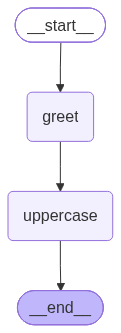

In [61]:
from IPython.display import Image
Image(finalGraph.get_graph().draw_mermaid_png())